# Gymnasium — environments, agents and returns

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s9-gymnasium-intro.ipynb)

**MS2A — Machine Learning Practice · Session 9, Reinforcement Learning**

Reinforcement learning studies an **agent** that interacts with an **environment**: at each
step the agent observes a state, chooses an action, and the environment returns a new
state and a reward. The objective is a policy that maximises the expected return.

| Section | What you do |
|---|---|
| 0 | Install Gymnasium 1.3.0 |
| 1 | A toy environment and a random agent, written by hand |
| 2 | Return and discounted return; the best policy vs the random one |
| 3 | Four Gymnasium environments: look at them, describe their spaces, dynamics and rewards |
| 4 | Run a random agent on each, measure its discounted return |

## 0. Setup

In [1]:
!pip install -q "gymnasium[box2d,other]==1.3.0" ale-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 48.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 46.3 MB/s eta 0:00:00


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)  # makes the Atari "ALE/..." environments available
print("gymnasium", gym.__version__)

gymnasium 1.3.0


## 1. A toy environment and a random agent

An environment exposes `reset()` (start an episode, return the first state) and
`step(action)`, which returns `(state, reward, terminated, truncated, info)` — the
Gymnasium convention.

In [2]:
class Env:
    def reset(self):
        self.state = np.random.randint(2)
        return self.state

    def step(self, action):
        reward = 1 if action % 2 == self.state else -1
        self.state = np.random.randint(2)
        return self.state, reward, False, False, {}

An agent maps a state to an action. This one ignores the state.

In [3]:
class Agent:
    def act(self, state):
        return np.random.randint(2)

An experiment runs the agent for `nb_steps` steps and records the trajectory and the rewards.

In [4]:
def run_experiment(env, agent, nb_steps):
    state = env.reset()
    trajectory, rewards = [state], []
    for _ in range(nb_steps):
        action = agent.act(state)
        state, reward, terminated, truncated, info = env.step(action)
        trajectory += [action, reward, state]
        rewards.append(reward)
    return trajectory, rewards

**Questions** — answer in this cell.

1. What is the **state space** of `Env`?
2. What is the **action space**?
3. What is the **transition model**? Does the next state depend on the action — is this a bandit problem?
4. What is the **policy** of `Agent`?
5. What is the **reward function**?
6. What does `run_experiment` return? In which order are the elements of `trajectory`?

**Exercise 1.** Instantiate `Env` and `Agent`, run an experiment of 100 steps, print the first 10 elements of the trajectory.

In [7]:
env = Env()    # TODO
agent = Agent()  # TODO
trajectory, rewards = run_experiment(env, agent, nb_steps = 100) # TODO
print(trajectory[:10])

[0, 1, -1, 1, 0, -1, 0, 1, -1, 1]


## 2. Return

The **return** from step $t$ is the discounted sum of the future rewards, with a discount
factor $\gamma \in [0, 1]$:

$$G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1} = R_{t+1} + \gamma\, G_{t+1}$$

With $\gamma = 1$ it is the plain cumulative reward.

**Exercise 2.** Write `compute_returns(rewards, gamma)`, which returns the list of $G_t$ for every
step $t$. Hint: go backwards, using $G_t = R_{t+1} + \gamma G_{t+1}$. Print $G_0$ and $G_{42}$ for
$\gamma = 1$ and $\gamma = 0.8$.

In [9]:
def compute_returns(rewards, gamma=1.0):
    returns = np.zeros(len(rewards))
    g = 0.0
    for t in reversed(range(len(rewards))):
        g = rewards[t] + gamma * g  # TODO
        returns[t] = g
    return returns

print(compute_returns(rewards)[[0, 42]], compute_returns(rewards, 0.8)[[0, 42]])

[-2.  6.] [-2.75574443  1.6432752 ]


**Questions**

7. What is the **expected return** $\mathbb{E}[G_0]$ of the random policy over 100 steps, with $\gamma = 1$?
8. What is the **best policy** for `Env`? What is its expected return?

**Exercise 3.** Implement the best policy in `BestAgent`, then compare it with the random agent
over 100 experiments of 100 steps.

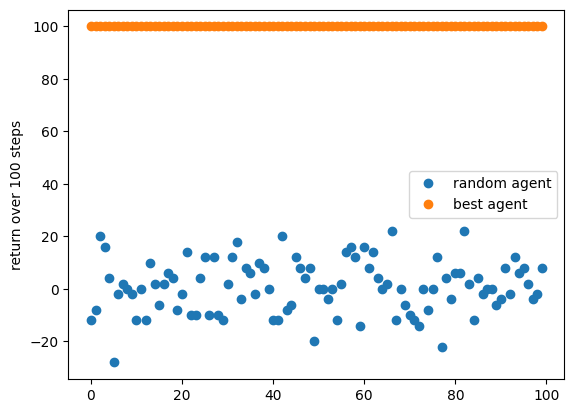

In [10]:
class BestAgent:
    def act(self, state):
        return state # TODO

env = Env()
random_returns = [sum(run_experiment(env, Agent(), 100)[1]) for _ in range(100)]
best_returns = [sum(run_experiment(env, BestAgent(), 100)[1]) for _ in range(100)]

plt.plot(random_returns, "o", label="random agent")
plt.plot(best_returns, "o", label="best agent")
plt.ylabel("return over 100 steps"); plt.legend(); plt.show()

## 3. Gymnasium environments

[Gymnasium](https://gymnasium.farama.org) is the standard interface for RL environments. Every
environment is created with `gym.make(name)`, and exposes `observation_space`, `action_space`,
`reset(seed=...)` and `step(action)`. With `render_mode="rgb_array"`, `env.render()` returns the
current frame as an image.

The helper below plays random actions and shows the episode as a video. Run it on the four
environments, and read each environment's documentation page while it runs:
[FrozenLake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/),
[CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/),
[LunarLander](https://gymnasium.farama.org/environments/box2d/lunar_lander/),
[Pong](https://ale.farama.org/environments/pong/).

In [11]:
import imageio
from IPython.display import Video, display

def show_random_episode(name, nb_steps, fps, **kwargs):
    env = gym.make(name, render_mode="rgb_array", **kwargs)
    env.reset(seed=0)
    frames = [env.render()]
    for _ in range(nb_steps):
        _, _, terminated, truncated, _ = env.step(env.action_space.sample())
        frames.append(env.render())
        if terminated or truncated:
            break
    imageio.mimsave(f"{name.replace('/', '_')}.mp4", frames, fps=fps, macro_block_size=1)
    display(Video(f"{name.replace('/', '_')}.mp4", embed=True, width=320))

In [12]:
ENVS = [
    ("FrozenLake-v1", {}),
    ("CartPole-v1", {}),
    ("LunarLander-v3", {"continuous": True}),
    ("ALE/Pong-v5", {}),
]
for name, kwargs in ENVS:
    env = gym.make(name, **kwargs)
    print(f"{name:16s} observation: {env.observation_space}   action: {env.action_space}")

FrozenLake-v1    observation: Discrete(16)   action: Discrete(4)
CartPole-v1      observation: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)   action: Discrete(2)
LunarLander-v3   observation: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)   action: Box(-1.0, 1.0, (2,), float32)
ALE/Pong-v5      observation: Box(0, 255, (210, 160, 3), uint8)   action: Discrete(6)


In [13]:
show_random_episode("FrozenLake-v1", nb_steps=30, fps=2)
show_random_episode("CartPole-v1", nb_steps=120, fps=20)
show_random_episode("LunarLander-v3", nb_steps=300, fps=30, continuous=True)
show_random_episode("ALE/Pong-v5", nb_steps=500, fps=30)

**Questions** — for each of FrozenLake-v1, CartPole-v1, LunarLander-v3 (continuous) and ALE/Pong-v5:

1. **Spaces.** Is the action space discrete or continuous, and what is its size or shape? Same for the state (observation) space.
2. **Transitions.** Is the transition model deterministic or stochastic? (FrozenLake: what does `is_slippery` change?)
3. **Reward.** What is the reward function? Is it dense (every step) or sparse?
4. **End of episode.** What makes an episode `terminated`, and what makes it `truncated`?

| | Action space | State space | Transitions | Reward | End of episode |
|---|---|---|---|---|---|
| FrozenLake-v1 | | | | | |
| CartPole-v1 | | | | | |
| LunarLander-v3 | | | | | |
| ALE/Pong-v5 | | | | | |

## 4. A random agent on Gymnasium

**Exercise 4.** Write `run_episode(env, agent)`, which plays one episode until `terminated` or
`truncated` and returns the list of rewards. Run it once on each environment and print the
cumulative reward and the number of steps.

In [14]:
class RandomAgent:
    def __init__(self, action_space):
        self.action_space = action_space

    def act(self, state):
        return self.action_space.sample()

def run_episode(env, agent, seed=None):
    state, info = env.reset(seed=seed)
    rewards = []
    while True:
        state, reward, terminated, truncated, info = env.step(agent.act(state))
        rewards.append(reward)
        if terminated or truncated:
            break
    # TODO: loop until terminated or truncated; append each reward
    return rewards

for name, kwargs in ENVS:
    env = gym.make(name, **kwargs)
    rewards = run_episode(env, RandomAgent(env.action_space), seed=0)
    print(f"{name:16s} cumulative reward: {sum(rewards):8.2f}   steps: {len(rewards)}")

FrozenLake-v1    cumulative reward:     0.00   steps: 17
CartPole-v1      cumulative reward:    37.00   steps: 37
LunarLander-v3   cumulative reward:   -61.86   steps: 74
ALE/Pong-v5      cumulative reward:   -20.00   steps: 1019


**Exercise 5.** Run 20 episodes per environment with the random agent and report the mean and
standard deviation of the discounted return $G_0$ with $\gamma = 0.95$ (use `compute_returns`).
Pong episodes are long: a random agent loses 21–0 in about 800 steps.

**Question.** Which environment would a random agent never solve, and why does that make
**exploration** the hard part of the problem?

In [15]:
for name, kwargs in ENVS:
    env = gym.make(name, **kwargs)
    g0 = [compute_returns(run_episode(env, RandomAgent(env.action_space), seed=i), 0.95)[0]for i in range(20)]  # TODO: 20 discounted returns G_0 (gamma = 0.95)
    print(f"{name:16s} G_0 = {np.mean(g0):7.3f} ± {np.std(g0):.3f}")

FrozenLake-v1    G_0 =   0.024 ± 0.106
CartPole-v1      G_0 =  12.109 ± 2.874
LunarLander-v3   G_0 = -15.970 ± 16.076
ALE/Pong-v5      G_0 =  -0.035 ± 0.018
